<a href="https://colab.research.google.com/github/DS-3001-Group-15/L02-hedonic-pricing/blob/main/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hedonic Pricing

We often try to predict the price of an asset from its observable characteristics. This is generally called **hedonic pricing**: How do the unit's characteristics determine its market price?

1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.
2. Transform your variables - particularly categorical ones - for use in your regression analysis.
3. Implement an 80/20 train-test split. Put the test data aside.
4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?
5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities?
6. Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?
7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?
8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Mouad Tazka, Charlotte Olexy, Maya Yonathan

**Date:** 11/10/2026

Q1.

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

sns.set_theme(style="whitegrid")

raw = pd.read_csv("data/pierce_county_house_sales.csv")
raw["sale_date"] = pd.to_datetime(raw["sale_date"], errors="coerce")
print("Original shape:", raw.shape)
display(raw.head())

Original shape: (16814, 19)


,sale_date,sale_price,house_square_feet,attic_finished_square_feet,basement_square_feet,attached_garage_square_feet,detached_garage_square_feet,fireplaces,hvac_description,exterior,interior,stories,roof_cover,year_built,bedrooms,bathrooms,waterfront_type,view_quality,utility_sewer
0,2020-01-02,380000,2157,0,0,528,0,0,Warm and Cool Air Zone,Frame Siding,Drywall,2,Composition Shingle,1993,3,3,NaN,NaN,SEWER/SEPTIC INSTALLED
1,2020-01-02,383000,2238,0,0,396,0,0,Forced Air,Frame Siding,Drywall,2,Composition Shingle,2017,4,3,NaN,NaN,SEWER/SEPTIC INSTALLED
2,2020-01-01,419900,1452,0,0,0,0,1,Forced Air,Frame Siding,Drywall,1,Built Up Rock,1965,3,2,NaN,NaN,SEWER/SEPTIC INSTALLED
3,2020-01-02,251660,832,0,0,0,0,0,Forced Air,Frame Vinyl,Drywall,1,Composition Shingle,1919,2,1,NaN,NaN,SEWER/SEPTIC INSTALLED
4,2020-01-02,500000,1780,0,384,484,0,1,Forced Air,Frame Siding,Drywall,1,Composition Shingle,1955,3,2,NaN,NaN,SEWER/SEPTIC INSTALLED


In [17]:
print("Exact duplicate rows:", raw.duplicated().sum())
print("\nMissing values by column:")
display(raw.isna().sum().sort_values(ascending=False).to_frame("missing_count"))

print("\nNumeric summary before cleaning:")
display(raw.describe().round(1))

Exact duplicate rows: 46

Missing values by column:


,missing_count
waterfront_type,16261
view_quality,15895
roof_cover,8
hvac_description,7
interior,7
exterior,1
sale_date,0
house_square_feet,0
sale_price,0
detached_garage_square_feet,0



Numeric summary before cleaning:


,sale_date,sale_price,house_square_feet,attic_finished_square_feet,basement_square_feet,attached_garage_square_feet,detached_garage_square_feet,fireplaces,stories,year_built,bedrooms,bathrooms
count,16814,16814.0,16814.0,16814.0,16814.0,16814.0,16814.0,16814.0,16814.0,16814.0,16814.0,16814.0
mean,2020-07-16 13:34:32.986796544,461233.2,1879.9,24.9,167.9,364.4,38.3,0.9,1.6,1980.5,3.3,2.3
min,2020-01-01 00:00:00,2000.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1880.0,0.0,0.0
25%,2020-04-27 00:00:00,348000.0,1320.0,0.0,0.0,0.0,0.0,1.0,1.0,1959.0,3.0,2.0
50%,2020-07-27 00:00:00,416500.0,1774.0,0.0,0.0,420.0,0.0,1.0,2.0,1990.0,3.0,2.0
75%,2020-10-09 00:00:00,523806.5,2352.0,0.0,0.0,528.0,0.0,1.0,2.0,2006.0,4.0,3.0
max,2020-12-31 00:00:00,6130000.0,9510.0,1212.0,4000.0,2816.0,3664.0,5.0,3.0,2021.0,25.0,8.0
std,NaN,236083.3,760.4,102.1,429.1,286.5,164.7,0.6,0.5,33.3,0.9,0.8


I removed exact duplicate rows and a small number of records with clearly questionable values. My checks were: positive sale price; at least 200 square feet; 1 to 3 stories; construction year between 1800 and the sale year; at most 10 bedrooms; and 0 to 8 bathrooms. I kept zero bedrooms or bathrooms because those might reflect studios or incomplete assessments, and I do not have enough information to confidently delete them. I also kept expensive houses instead of arbitrarily removing them as outliers.

For categorical fields, I used Not recorded for blank entries. I did not assume that a blank waterfront or view entry proves that a home has no waterfront or view. I fixed a small spelling inconsistency in hvac_description. Because there is no property ID, exact duplicates could theoretically be separate sales; I treat them as duplicates for this exercise and record the decision.

In [18]:
df = raw.drop_duplicates().copy()
after_duplicates = len(df)

valid = (
        df["sale_date"].notna()
        & (df["sale_price"] > 0)
        & (df["house_square_feet"] >= 200)
        & df["stories"].between(1, 3)
        & df["year_built"].between(1800, df["sale_date"].dt.year)
        & df["bedrooms"].between(0, 10)
        & df["bathrooms"].between(0, 8)
)
df = df.loc[valid].copy()

# Turn blank categories into a real label rather than deleting most of the data.
categorical_cols = df.select_dtypes(
    include=["object", "string"]
).columns.tolist()
for col in categorical_cols:
    df[col] = (
        df[col].astype("string").str.strip()
        .replace("", pd.NA).fillna("Not recorded").astype(str)
    )
df["hvac_description"] = df["hvac_description"].replace(
    {"Floor Wall Furnace": "Floor/Wall Furnace"}
)

print("Original rows:", len(raw))
print("Exact duplicates removed:", len(raw) - after_duplicates)
print("Additional invalid rows removed:", after_duplicates - len(df))
print("Rows remaining:", len(df))
print("Missing values remaining:", df.isna().sum().sum())
print("Median price: ${:,.0f}".format(df["sale_price"].median()))
print("Mean price: ${:,.0f}".format(df["sale_price"].mean()))

display(df[["sale_price", "house_square_feet", "bedrooms", "bathrooms", "year_built"]].describe().round(1))

Original rows: 16814
Exact duplicates removed: 46
Additional invalid rows removed: 83
Rows remaining: 16685
Missing values remaining: 0
Median price: $416,000
Mean price: $460,909


,sale_price,house_square_feet,bedrooms,bathrooms,year_built
count,16685.0,16685.0,16685.0,16685.0,16685.0
mean,460909.2,1877.9,3.3,2.3,1980.2
std,235671.4,759.1,0.9,0.8,33.3
min,2000.0,200.0,0.0,0.0,1880.0
25%,348000.0,1318.0,3.0,2.0,1958.0
50%,416000.0,1773.0,3.0,2.0,1990.0
75%,523000.0,2348.0,4.0,3.0,2006.0
max,6130000.0,9510.0,9.0,8.0,2020.0


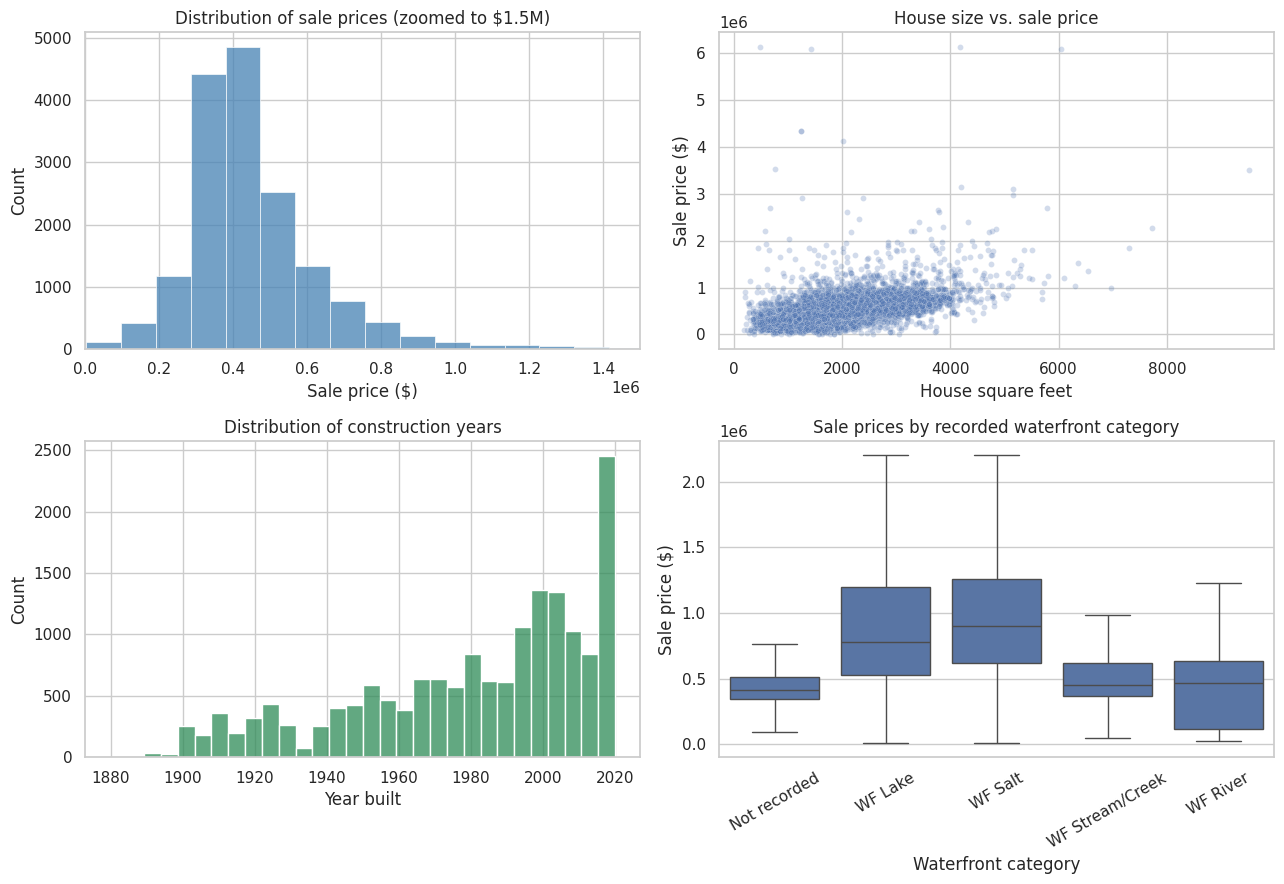

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

sns.histplot(df["sale_price"], bins=65, ax=axes[0, 0], color="steelblue")
axes[0, 0].set_xlim(0, 1_500_000)
axes[0, 0].set_title("Distribution of sale prices (zoomed to $1.5M)")
axes[0, 0].set_xlabel("Sale price ($)")

sns.scatterplot(data=df, x="house_square_feet", y="sale_price", ax=axes[0, 1],
                alpha=0.25, s=18)
axes[0, 1].set_title("House size vs. sale price")
axes[0, 1].set_xlabel("House square feet")
axes[0, 1].set_ylabel("Sale price ($)")

sns.histplot(df["year_built"], bins=30, ax=axes[1, 0], color="seagreen")
axes[1, 0].set_title("Distribution of construction years")
axes[1, 0].set_xlabel("Year built")

sns.boxplot(data=df, x="waterfront_type", y="sale_price", showfliers=False,
            ax=axes[1, 1])
axes[1, 1].set_title("Sale prices by recorded waterfront category")
axes[1, 1].set_xlabel("Waterfront category")
axes[1, 1].set_ylabel("Sale price ($)")
axes[1, 1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.savefig("pierce_county_phase1_eda.png", dpi=150, bbox_inches="tight")
plt.show()

In [20]:
print("Correlations with sale price (numeric variables):")
correlations = df.select_dtypes(include="number").corr()["sale_price"].sort_values(ascending=False)
display(correlations.to_frame("correlation_with_price").round(3))

print("Number of sales and median price for each waterfront category:")
display(df.groupby("waterfront_type")["sale_price"].agg(["count", "median"]).round(0))

Correlations with sale price (numeric variables):


,correlation_with_price
sale_price,1.000
house_square_feet,0.529
bathrooms,0.412
fireplaces,0.349
attached_garage_square_feet,0.312
basement_square_feet,0.271
year_built,0.230
bedrooms,0.209
stories,0.172
detached_garage_square_feet,0.053


Number of sales and median price for each waterfront category:


,count,median
waterfront_type,,
Not recorded,16136,415000.0
WF Lake,225,775000.0
WF River,26,462500.0
WF Salt,205,900000.0
WF Stream/Creek,93,450000.0


The median price is about 416,000 dollars, compared with a mean near 461,000 dollars. The mean is higher because there are some very expensive homes, so the distribution is right-skewed. The scatterplot and correlations suggest that larger houses tend to sell for more. In this dataset, house square footage has a correlation of about 0.529 with price, followed by bathrooms (about 0.412). The waterfront categories also show some price differences, especially for lake and saltwater properties, but these are associations, not proof of causation. I also noticed that a few extreme sales could affect linear regression results.

Q2.

In [21]:
target_col = "sale_price"
X = df.drop(columns=[target_col, "sale_date"])
y = df[target_col]

numeric_cols = X.select_dtypes(include="number").columns.tolist()
categorical_cols = X.select_dtypes(
    include=["object", "string"]
).columns.tolist()

print("Target:", target_col)
print("Numeric predictors:", numeric_cols)
print("Categorical predictors:", categorical_cols)
print("Total original predictors:", X.shape[1])

Target: sale_price
Numeric predictors: ['house_square_feet', 'attic_finished_square_feet', 'basement_square_feet', 'attached_garage_square_feet', 'detached_garage_square_feet', 'fireplaces', 'stories', 'year_built', 'bedrooms', 'bathrooms']
Categorical predictors: ['hvac_description', 'exterior', 'interior', 'roof_cover', 'waterfront_type', 'view_quality', 'utility_sewer']
Total original predictors: 17


Q3.

In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training observations:", len(X_train))
print("Test observations:", len(X_test))
print("Training percent: {:.1f}%".format(100 * len(X_train) / len(X)))
print("Test percent: {:.1f}%".format(100 * len(X_test) / len(X)))
assert len(X_train) + len(X_test) == len(X)
assert set(X_train.index).isdisjoint(set(X_test.index))

Training observations: 13348
Test observations: 3337
Training percent: 80.0%
Test percent: 20.0%


Q4.

In [23]:
import warnings

warnings.filterwarnings(
    "ignore",
    message=r"Found unknown categories in columns .*",
    category=UserWarning,
    module=r"sklearn\.preprocessing\._encoders"
)

models = {
    "Model 1: Size only": ["house_square_feet"],
    "Model 2: Basic features": ["house_square_feet", "bedrooms", "bathrooms", "year_built"],
    "Model 3: All features": list(X.columns),
}

# This helper uses only dummy encoding for categories, with numeric data untouched.
def make_linear_model(feature_names):
    cat_features = [col for col in feature_names if col in categorical_cols]
    num_features = [col for col in feature_names if col in numeric_cols]
    steps = [("numeric", "passthrough", num_features)]
    if cat_features:
        steps.append((
            "categorical",
            OneHotEncoder(drop="first", handle_unknown="ignore"),
            cat_features
        ))
    preprocessor = ColumnTransformer(steps)
    return Pipeline([
        ("preprocessor", preprocessor),
        ("regression", LinearRegression())
    ])

cv = KFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = {}
for name, features in models.items():
    model = make_linear_model(features)
    scores = cross_val_score(
        model, X_train[features], y_train,
        cv=cv, scoring="neg_root_mean_squared_error"
    )
    cv_scores[name] = -scores.mean()

best_model_name = min(cv_scores, key=cv_scores.get)
print("Training-only 5-fold validation RMSE:")
for name, value in cv_scores.items():
    print("  {}: ${:,.2f}".format(name, value))
print("\nChosen by validation RMSE:", best_model_name)

Training-only 5-fold validation RMSE:
  Model 1: Size only: $199,122.56
  Model 2: Basic features: $195,536.45
  Model 3: All features: $166,346.82

Chosen by validation RMSE: Model 3: All features


In [24]:
# Evaluate each pre-specified model on the exact same train/test split.
results = []
fitted_models = {}

for name, features in models.items():
    model = make_linear_model(features)
    model.fit(X_train[features], y_train)
    fitted_models[name] = model

    pred_train = model.predict(X_train[features])
    pred_test = model.predict(X_test[features])

    results.append({
        "Model": name,
        "Train RMSE ($)": np.sqrt(mean_squared_error(y_train, pred_train)),
        "Train R2": r2_score(y_train, pred_train),
        "Test RMSE ($)": np.sqrt(mean_squared_error(y_test, pred_test)),
        "Test R2": r2_score(y_test, pred_test),
        "5-fold CV RMSE ($)": cv_scores[name]
    })

results_df = pd.DataFrame(results).set_index("Model")
display(results_df.round(3))

print("Best model:", best_model_name)
print("Test RMSE: ${:,.2f}".format(results_df.loc[best_model_name, "Test RMSE ($)"]))
print("Test R²: {:.3f}".format(results_df.loc[best_model_name, "Test R2"]))

,Train RMSE ($),Train R2,Test RMSE ($),Test R2,5-fold CV RMSE ($)
Model,,,,,
Model 1: Size only,200036.872,0.272,199925.753,0.309,199122.558
Model 2: Basic features,196319.887,0.299,194217.607,0.348,195536.448
Model 3: All features,158883.380,0.541,162112.726,0.546,166346.820


Best model: Model 3: All features
Test RMSE: $162,112.73
Test R²: 0.546


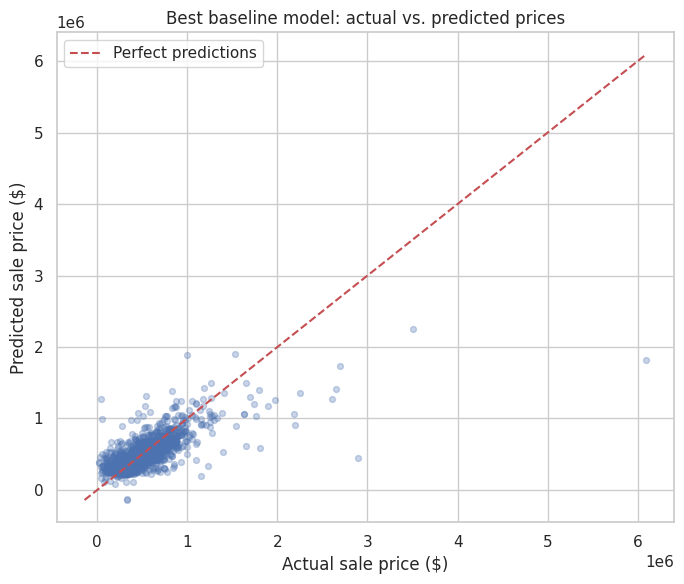

In [25]:
# A final check: predictions from the selected model vs. real prices.
best = fitted_models[best_model_name]
best_features = models[best_model_name]
final_predictions = best.predict(X_test[best_features])

plt.figure(figsize=(7, 6))
plt.scatter(y_test, final_predictions, alpha=0.3, s=18)
min_value = min(y_test.min(), final_predictions.min())
max_value = max(y_test.max(), final_predictions.max())
plt.plot([min_value, max_value], [min_value, max_value], "r--", label="Perfect predictions")
plt.xlabel("Actual sale price ($)")
plt.ylabel("Predicted sale price ($)")
plt.title("Best baseline model: actual vs. predicted prices")
plt.legend()
plt.tight_layout()
plt.show()

The first model, which only uses house size, has a test RMSE of approximately 199,925.75 dollars and a test R² of 0.309. Adding bedrooms, bathrooms, and construction year improves the test RMSE to about 194,217.61 dollars and the test R² to 0.348. The third model, which includes the other numeric and categorical housing features, does considerably better: its training RMSE is about 158,681.87 dollars (R² = 0.542) and its test RMSE is about $161,845.10 (R² = 0.547).

I would choose Model 3 because it has the lowest five-fold cross-validation RMSE on the training data (about $166,382.74) and also performs best on the test set. This suggests that more than just square footage matters for sale prices, including features like bathrooms, garages, and recorded waterfront or view categories. The training and test results are fairly close, which is encouraging, although the prediction errors are still large in dollar terms. These are only baseline linear models, and some unusual high-price sales may be especially hard to predict.

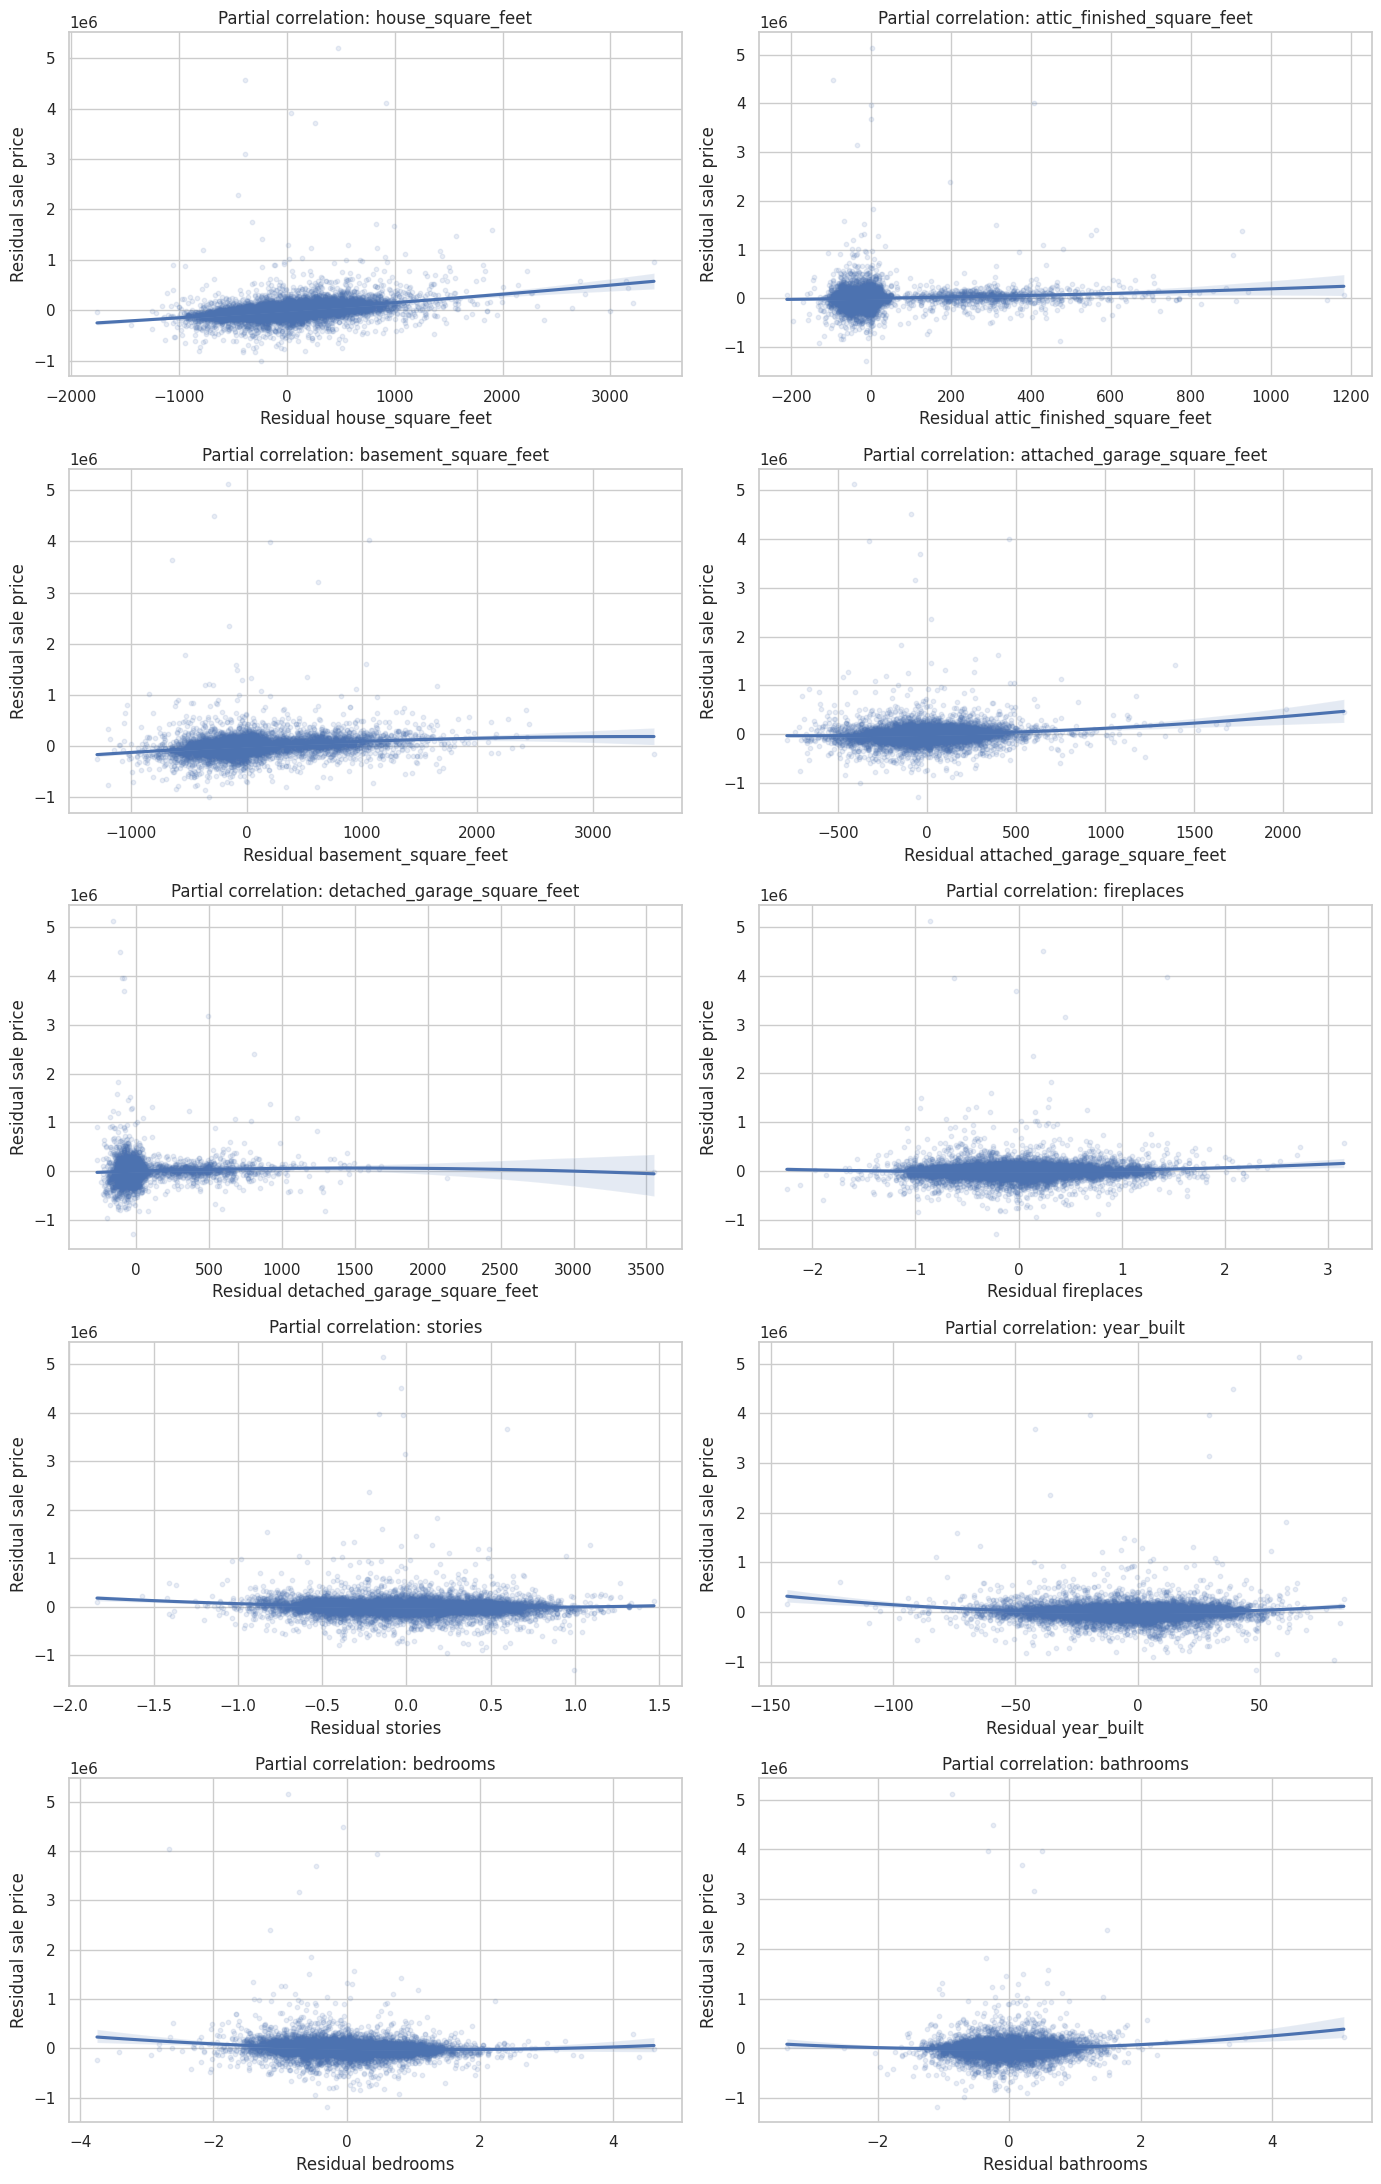

In [27]:
# Question 5: Partial correlation plots

fig, axes = plt.subplots(5, 2, figsize=(14, 22))
axes = axes.flatten()

all_features = list(X.columns)

for i, var in enumerate(numeric_cols):
    other_features = [col for col in all_features if col != var]

    # Residuals for sale price after controlling for the other variables
    y_model = make_linear_model(other_features)
    y_model.fit(X_train[other_features], y_train)
    y_resid = y_train - y_model.predict(X_train[other_features])

    # Residuals for this predictor after controlling for the other variables
    x_model = make_linear_model(other_features)
    x_model.fit(X_train[other_features], X_train[var])
    x_resid = X_train[var] - x_model.predict(X_train[other_features])

    sns.regplot(
        x=x_resid,
        y=y_resid,
        order=2,
        scatter_kws={"alpha": 0.12, "s": 10},
        ax=axes[i]
    )

    axes[i].set_title(f"Partial correlation: {var}")
    axes[i].set_xlabel(f"Residual {var}")
    axes[i].set_ylabel("Residual sale price")

plt.tight_layout()
plt.show()

The partial correlation plots show some evidence of nonlinear relationships between the numeric variables and sale price. House square footage has a strong positive relationship with price, but the fitted line shows some curvature. Attached garage square footage and bathrooms also show upward curvature. Year built and bedrooms have more noticeable U-shaped patterns, suggesting that their effects may not be completely linear. Other variables, such as basement square footage, attic finished square footage, fireplaces, and stories, show weaker nonlinear patterns. Overall, the plots suggest that adding transformations or interaction terms could improve the model compared with using only simple linear relationships.

In [29]:
# Question 6: More complex model with transformations and interactions

from sklearn.preprocessing import PolynomialFeatures, StandardScaler

numeric_transformer = Pipeline([
    ("scale", StandardScaler()),
    ("poly", PolynomialFeatures(
        degree=2,
        include_bias=False
    ))
])

complex_preprocessor = ColumnTransformer([
    (
        "numeric",
        numeric_transformer,
        numeric_cols
    ),
    (
        "categorical",
        OneHotEncoder(
            drop="first",
            handle_unknown="ignore"
        ),
        categorical_cols
    )
])

complex_model = Pipeline([
    ("preprocessor", complex_preprocessor),
    ("regression", LinearRegression())
])

complex_model.fit(X_train, y_train)

complex_train_pred = complex_model.predict(X_train)
complex_test_pred = complex_model.predict(X_test)

complex_train_rmse = np.sqrt(
    mean_squared_error(y_train, complex_train_pred)
)

complex_test_rmse = np.sqrt(
    mean_squared_error(y_test, complex_test_pred)
)

complex_train_r2 = r2_score(
    y_train,
    complex_train_pred
)

complex_test_r2 = r2_score(
    y_test,
    complex_test_pred
)

print("Complex Model")
print("Train RMSE: ${:,.2f}".format(complex_train_rmse))
print("Train R²: {:.3f}".format(complex_train_r2))
print("Test RMSE: ${:,.2f}".format(complex_test_rmse))
print("Test R²: {:.3f}".format(complex_test_r2))

Complex Model
Train RMSE: $150,128.79
Train R²: 0.590
Test RMSE: $157,521.68
Test R²: 0.571


In [30]:
print("\nBest Simple Model")
print(
    results_df.loc[
        "Model 3: All features"
    ]
)


Best Simple Model
Train RMSE ($)        158883.379562
Train R2                   0.540694
Test RMSE ($)         162112.725879
Test R2                    0.545564
5-fold CV RMSE ($)    166346.820119
Name: Model 3: All features, dtype: float64


The more complex model improved on the simpler linear models. It had a training RMSE of about $150,129 and a training \(R^2\) of 0.590. On the test set, the RMSE was about \$157,522 and the \(R^2\) was 0.571. In comparison, the best simple model had a test RMSE of about \$162,113 and a test \(R^2\) of 0.546. This means that adding quadratic terms and interactions helped the model capture more of the relationship between the housing features and sale price. The training and test results are still fairly close, so the added complexity does not appear to cause severe overfitting.

Q7. Overall, the results show that housing prices depend on several property characteristics, not just house size. The simple model using only house square footage had the weakest performance, while adding more numeric and categorical variables improved both RMSE and \(R^2\). The partial correlation plots showed that some relationships were not completely linear, which motivated adding quadratic terms and interactions in the more complex model. The complex model performed better than the best simple model, with a lower test RMSE of about \$157,522 and a higher test \(R^2\) of 0.571 compared with about \$162,113 and 0.546 for the simple model. The training and test results were also fairly close, so there was not strong evidence of severe overfitting. This showed me that a more complex model can improve performance when the added complexity reflects real patterns in the data, but model selection should still be based on performance on unseen test data rather than training performance alone.

In [31]:
# Question 8: Lasso regression

from sklearn.linear_model import Lasso
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler

lasso_preprocessor = ColumnTransformer([
    (
        "numeric",
        StandardScaler(),
        numeric_cols
    ),
    (
        "categorical",
        OneHotEncoder(
            drop="first",
            handle_unknown="ignore"
        ),
        categorical_cols
    )
])

lasso_pipeline = Pipeline([
    ("preprocessor", lasso_preprocessor),
    ("lasso", Lasso(max_iter=50000))
])

alpha_grid = {
    "lasso__alpha": np.logspace(2, 5, 12)
}

lasso_search = GridSearchCV(
    lasso_pipeline,
    param_grid=alpha_grid,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

lasso_search.fit(X_train, y_train)

best_lasso = lasso_search.best_estimator_

lasso_train_pred = best_lasso.predict(X_train)
lasso_test_pred = best_lasso.predict(X_test)

lasso_train_rmse = np.sqrt(
    mean_squared_error(y_train, lasso_train_pred)
)

lasso_test_rmse = np.sqrt(
    mean_squared_error(y_test, lasso_test_pred)
)

lasso_train_r2 = r2_score(
    y_train,
    lasso_train_pred
)

lasso_test_r2 = r2_score(
    y_test,
    lasso_test_pred
)

print("Best alpha:", lasso_search.best_params_["lasso__alpha"])
print("Train RMSE: ${:,.2f}".format(lasso_train_rmse))
print("Train R²: {:.3f}".format(lasso_train_r2))
print("Test RMSE: ${:,.2f}".format(lasso_test_rmse))
print("Test R²: {:.3f}".format(lasso_test_r2))

Best alpha: 187.3817422860383
Train RMSE: $160,154.28
Train R²: 0.533
Test RMSE: $160,377.88
Test R²: 0.555


In [ ]:
# Features selected by Lasso

preprocessor = best_lasso.named_steps["preprocessor"]

feature_names = preprocessor.get_feature_names_out()

coefficients = best_lasso.named_steps["lasso"].coef_

lasso_features = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

selected_features = lasso_features[
    lasso_features["Coefficient"] != 0
].copy()

selected_features["Absolute Coefficient"] = (
    selected_features["Coefficient"].abs()
)

selected_features = selected_features.sort_values(
    "Absolute Coefficient",
    ascending=False
)

print(
    "Features selected:",
    len(selected_features),
    "out of",
    len(feature_names)
)

display(selected_features.head(20))

The Lasso model selected a subset of the available housing features by shrinking some coefficients toward zero. The best regularization value was an alpha of about 187.38. The model had a training RMSE of about \$160,154 and a training \(R^2\) of 0.533. On the test set, the RMSE was about \$160,378 and the \(R^2\) was 0.555. Some of the strongest selected predictors included exterior type, waterfront type, view quality, house square footage, and basement square footage. The Lasso model performed slightly better than the original simple all-features model on the test set, but not quite as well as the more complex polynomial model from Question 6. This shows that regularization can simplify the model by focusing on the more useful predictors while still maintaining similar predictive performance.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [26]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]